# MajiAlert Kenya: Final ML Engine (Logistic Regression)
**ICS 3202 Project Deliverable 3** · ICS3 Group B · 189944,191652, 192230

This notebook is the complete, final logic of the MajiAlert flood-risk engine, from raw data to the file the mobile app uses. It follows the stages of the data mining process (CRISP-DM):

1. Business understanding
2. Data understanding
3. Data preparation
4. Modelling
5. Evaluation
6. Deployment

The base model is in `notebooks/LogisticRegression_Base.ipynb`. The rules for improving it are in `docs/IMPROVEMENT_PROTOCOL.md`.

**To run:** put the raw files in `data/raw/` (see the README), then run all cells from top to bottom.

In [1]:
# Setup: run everything from the repository root so every pipeline script finds its files
import os, sys, json, math
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit

pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)
print("working in", ROOT)

working in c:\UNI\YR 3\3.2\Artificial Intelligence\Project


## 1. Business understanding

Floods are Kenya's most frequent weather disaster; the 2024 long rains killed 291 people. Official advisories from the Kenya Meteorological Department (KMD) forecast heavy rain for groups of counties, but they do not say how likely flooding is in each county. Our end user is a county disaster officer who has to decide where to send limited resources first. The question our model answers is: given the rain that has fallen so far, how likely is a recorded flood in this county in this ten-day period? Success means doing better than the simple rainfall rules people use today.

## 2. Data understanding

### 2.1 Rainfall: CHIRPS satellite estimates (HDX)

CHIRPS (Climate Hazards Group InfraRed Precipitation with Station data) estimates rainfall from satellite images and corrects it with rain gauges. We use it because Kenya has too few gauges to cover every county. A **dekad** is a ten-day period (days 1-10, 11-20 and 21 to the end of the month), so there are 36 in a year. Main columns: `rfh` is this dekad's rain in mm, `rfh_avg` is the normal for this dekad, `r1h`/`r3h` are the last one and three months, and `rfq`/`r1q`/`r3q` are those amounts as a percent of normal.

In [2]:
raw = pd.read_csv("data/raw/ken-rainfall-subnat-full.csv", parse_dates=["date"])
print("raw shape:", raw.shape)
print("dates:", raw.date.min().date(), "to", raw.date.max().date())
print("areas per admin level:", raw.groupby("adm_level").PCODE.nunique().to_dict())
raw.head()

raw shape: (133488, 15)
dates: 1981-01-01 to 2026-10-01
areas per admin level: {1: 8, 2: 73}


,date,adm_level,adm_id,PCODE,n_pixels,rfh,rfh_avg,r1h,r1h_avg,r3h,r3h_avg,rfq,r1q,r3q,version
0,1981-01-01,1,51325,KE019,427.0,7.372365,15.759407,NaN,NaN,NaN,NaN,59.598840,NaN,NaN,final
1,1981-01-11,1,51325,KE019,427.0,4.325527,19.294770,NaN,NaN,NaN,NaN,38.384920,NaN,NaN,final
2,1981-01-21,1,51325,KE019,427.0,5.569087,16.265417,17.266980,51.319595,NaN,NaN,49.700817,39.536823,NaN,final
3,1981-02-01,1,51325,KE019,427.0,5.882904,12.719282,15.777517,48.279470,NaN,NaN,61.418427,38.997230,NaN,final
4,1981-02-11,1,51325,KE019,427.0,17.180328,18.768618,28.632318,47.753320,NaN,NaN,93.317700,63.753933,NaN,final


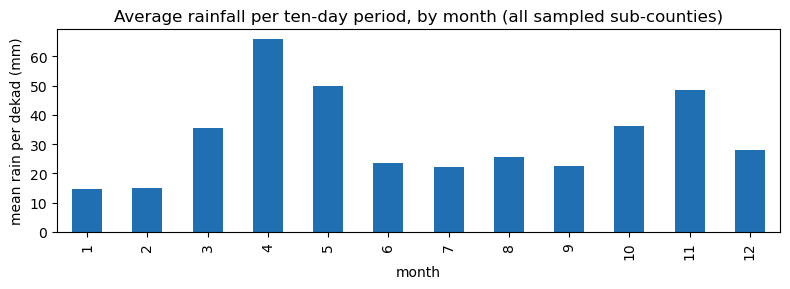

In [3]:
# Kenya's two rainy seasons: long rains (Mar-May) and short rains (Oct-Dec)
sub = raw[raw.adm_level == 2]
monthly = sub.groupby(sub.date.dt.month).rfh.mean()
ax = monthly.plot(kind="bar", figsize=(8, 3), color="#1F6FB2")
ax.set_xlabel("month"); ax.set_ylabel("mean rain per dekad (mm)")
ax.set_title("Average rainfall per ten-day period, by month (all sampled sub-counties)")
plt.tight_layout(); plt.show()

### 2.2 Flood records: DesInventar and EM-DAT

DesInventar is Kenya's national disaster loss database and EM-DAT (Emergency Events Database) is a global database run by CRED at UCLouvain. Together they tell us when and where floods happened. Their weaknesses: some floods were never recorded, some dates are approximate, and some records only name a province, not a county.

In [4]:
di = pd.read_csv("data/raw/DesInventar_Geocoded.csv", low_memory=False)
em = pd.read_csv("data/raw/EMDAT_Geocoded.csv", low_memory=False)
print("DesInventar rows:", len(di), "| EM-DAT rows:", len(em))
from pipeline.county_match import to_pcode, counties_in
for name in ["Kisumu", "HOMABAY", "Nyando", "Tarkana", "Thika"]:
    print(f"{name:10s} -> {to_pcode(name)}")
print(counties_in("Athi River (Machakos), Kitui, Tana River districts"))

DesInventar rows: 122693 | EM-DAT rows: 6132
Kisumu     -> KE042
HOMABAY    -> KE043
Nyando     -> KE042
Tarkana    -> KE023
Thika      -> KE022
({'KE016', 'KE004', 'KE015'}, [])


## 3. Data preparation

### 3.1 Cleaning checks

We keep only the 73 sub-county series, because the 8 county-level rows include a duplicate copy of Nairobi. The study window is 2002 to 2024. Percent of normal is calculated as `100 x (rain + 5) / (normal + 5)`; the +5 stops very dry places with a tiny normal from producing huge, meaningless percentages. The check below confirms this is exactly how the dataset computes it.

In [5]:
rain = raw[raw.adm_level == 2]
rain = rain[(rain.date >= "2002-01-01") & (rain.date < "2025-01-01")]
print("rows:", len(rain), "| sub-counties:", rain.PCODE.nunique(), "| counties covered:", rain.PCODE.str[:5].nunique())
print("missing values in the window:", int(rain[["rfh", "r1h", "r3h", "rfq", "r1q", "r3q"]].isna().sum().sum()))

# confirm the dataset's own percent-of-normal definition
plus5 = 100 * (rain.rfh + 5) / (rain.rfh_avg + 5)
plain = 100 * rain.rfh / rain.rfh_avg.replace(0, np.nan)
print("max gap, +5 formula vs file:", round(float((plus5 - rain.rfq).abs().max()), 4))
print("max gap, plain ratio vs file:", round(float((plain - rain.rfq).abs().max()), 1))

rows: 60444 | sub-counties: 73 | counties covered: 47
missing values in the window: 0
max gap, +5 formula vs file: 0.0001
max gap, plain ratio vs file: 582.5


### 3.2 Labels: turning flood records into flooded = 1 / 0

A label says whether a place flooded (1) or not (0) in a dekad. Each flood record marks every sampled sub-county of its county as flooded for every dekad the record covers. Records longer than 60 days are cut to 60, because some describe a whole rainy season rather than one flood. Records that only name a province are dropped, because labelling every county in a province would invent floods that did not happen.

In [6]:
%run pipeline/make_labels.py

records: 763 | by source: {'DesInventar': 449, 'EM-DAT': 314}
records longer than 30 days: 160
cap=None: 2670 positive rows of 60444 (4.42%)
cap=60: 2557 positive rows of 60444 (4.23%)
cap=30: 2072 positive rows of 60444 (3.43%)

saved data/processed/labels.csv with cap = 60

Nairobi MAM 2024:
   PCODE       date source  record_days  flooded  weight
KE047277 2024-03-01    NaN          NaN        0     1.0
KE047277 2024-03-11    NaN          NaN        0     1.0
KE047277 2024-03-21 EM-DAT         40.0        1     0.1
KE047277 2024-04-01 EM-DAT         40.0        1     0.1
KE047277 2024-04-11 EM-DAT          1.0        1     1.0
KE047277 2024-04-21 EM-DAT          1.0        1     1.0
KE047277 2024-05-01 EM-DAT         40.0        1     0.1
KE047277 2024-05-11    NaN          NaN        0     1.0
KE047277 2024-05-21    NaN          NaN        0     1.0


### 3.3 Feature engineering

Features are the numbers the model looks at, and they only use the present and the past, never the future (otherwise the model would be cheating; this is called leakage). Lags are the rain one and two dekads ago. The season is given as a point on a circle (`season_sin`, `season_cos`) so late December sits next to early January. `nat_frac_anom` is the share of Kenya getting double its normal rain, which separates a local storm from a country-wide wet season. We do not use the year or the county code, because they would teach the model how floods were reported, not how rain causes floods.

In [7]:
%run pipeline/make_features.py

rows: 60444 | positives: 2557 (4.23%)
missing values per feature (should all be 0):
rfh              0
rfh_avg          0
rfq              0
r1h              0
r3h              0
r1q              0
r3q              0
rfh_lag1         0
rfh_lag2         0
rfq_lag1         0
season_sin       0
season_cos       0
nat_frac_anom    0

median feature value, flooded vs not:
flooded             0       1
rfh             20.96   51.95
rfh_avg         27.60   40.23
rfq             91.44  128.38
r1h             77.46  173.06
r3h            271.49  364.09
r1q             95.22  140.24
r3q             99.57  130.94
rfh_lag1        20.90   53.56
rfh_lag2        21.06   46.50
rfq_lag1        91.23  131.17
season_sin      -0.00    0.50
season_cos      -0.00    0.00
nat_frac_anom    0.00    0.10

saved data/processed/features.csv


### 3.4 From sub-county to county

The unit is the county because the flood records are county-level and county officers are the people who act. Each county row takes the mean of its sampled sub-counties' rain features, plus the wettest sub-county (`_max`) and the shared features. A county counts as flooded if any of its sampled sub-counties is flooded.

In [8]:
%run pipeline/make_county.py

counties: 47 | rows: 38916 | flooded: 1546 (3.97%)
sampled sub-counties per county: min 1 max 4
county dekads where sampled sub-counties disagree on the label: 0


In [9]:
from pipeline.improve_cv import COUNTY_BASE, make_model, cv_run, recall_at_rule_precision
df = pd.read_csv("data/processed/county_features.csv", parse_dates=["date"])
print("county table:", df.shape, "| flooded share:", round(df.flooded.mean(), 4))
print("the 17 model features:", COUNTY_BASE)
df[["county", "date"] + COUNTY_BASE + ["flooded"]].describe().T[["mean", "min", "max"]].round(2)

county table: (38916, 27) | flooded share: 0.0397
the 17 model features: ['rfh', 'rfh_avg', 'rfq', 'r1h', 'r3h', 'r1q', 'r3q', 'rfh_lag1', 'rfh_lag2', 'rfq_lag1', 'rfh_max', 'rfq_max', 'r1q_max', 'r3q_max', 'season_sin', 'season_cos', 'nat_frac_anom']


,mean,min,max
date,2013-06-26 07:49:33.913043712,2002-01-01 00:00:00,2024-12-21 00:00:00
rfh,31.879697,0.001205,442.473287
rfh_avg,29.840488,0.001727,131.64333
rfq,104.465745,10.224658,687.95557
r1h,95.58292,0.175904,887.127553
r3h,286.283148,2.139759,1385.054933
r1q,104.97918,15.307993,529.7614
r3q,105.856092,22.055058,432.7239
rfh_lag1,31.859327,0.001205,442.473287
rfh_lag2,31.843896,0.001205,442.473287


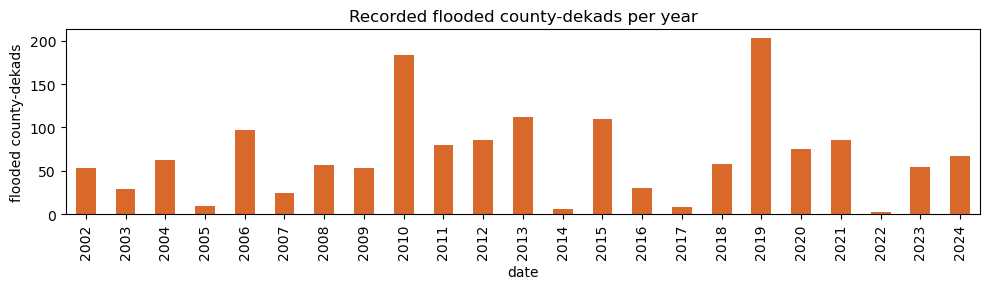

In [10]:
# floods recorded per year: reporting drops after 2016, which matters for testing
per_year = df.groupby(df.date.dt.year).flooded.sum()
ax = per_year.plot(kind="bar", figsize=(10, 3), color="#D9692A")
ax.set_ylabel("flooded county-dekads"); ax.set_title("Recorded flooded county-dekads per year")
plt.tight_layout(); plt.show()

## 4. Modelling

### 4.1 Splitting by time

We split by time, not at random. In real use the model predicts the future from the past, and one storm affects many counties at once, so a random split would leak information between training and testing. We train on 2002-2019 and keep 2020-2024 locked for a single final test.

In [11]:
train = df[df.date < "2020-01-01"].copy()
test = df[df.date >= "2020-01-01"].copy()
print("train:", len(train), "rows,", int(train.flooded.sum()), "floods, base rate", round(train.flooded.mean(), 3))
print("test: ", len(test), "rows,", int(test.flooded.sum()), "floods, base rate", round(test.flooded.mean(), 3))

train: 30456 rows, 1261 floods, base rate 0.041
test:  8460 rows, 285 floods, base rate 0.034


### 4.2 The model: logistic regression

Logistic regression standardises each feature, multiplies it by a learned weight, adds them up, and squashes the total into a probability between 0 and 1 with the sigmoid function. Floods are only about 4% of rows, so `class_weight='balanced'` makes each flood count more during training. C = 0.001 means strong regularisation, which keeps the weights small and the model simple. We chose it because the data is small and noisy, the model can explain every prediction, and it is small enough to run on a phone.

In [12]:
make_model()

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=0.001, class_weight='balanced',
                                    max_iter=1000, random_state=42))])

### 4.3 Cross-validation on the training years

Cross-validation tests the model several times on parts of the training years it did not train on. `TimeSeriesSplit` always validates on later periods than it trains on, and we split on whole dekads so the same storm never sits on both sides. We score with PR-AUC (precision-recall area under the curve), which measures how well the model ranks flooded periods above dry ones; a random guess scores the share of floods. We do not use accuracy, because always saying 'no flood' would already score 96%.

In [13]:
scores, oof = cv_run(train, COUNTY_BASE, rule_cols=("rfh_max", "rfq_max"))
base = train.flooded.mean()
print("PR-AUC per fold:", [round(s, 3) for s in scores])
print(f"mean PR-AUC {np.mean(scores):.3f}  | base rate {base:.3f}  | lift {np.mean(scores)/base:.1f}x")

PR-AUC per fold: [np.float64(0.119), np.float64(0.199), np.float64(0.236), np.float64(0.074), np.float64(0.35)]
mean PR-AUC 0.196  | base rate 0.041  | lift 4.7x


In [14]:
# choosing C: every value scores about the same, so the strongest penalty (simplest model) is kept
import pipeline.improve_cv as icv
rows = []
for c in [0.001, 0.01, 0.1, 1, 10]:
    icv.C = c
    s, _ = cv_run(train, COUNTY_BASE, rule_cols=("rfh_max", "rfq_max"))
    rows.append({"C": c, "mean PR-AUC": round(np.mean(s), 3)})
icv.C = 0.001
pd.DataFrame(rows)

,C,mean PR-AUC
0,0.001,0.196
1,0.010,0.192
2,0.100,0.189
3,1.000,0.188
4,10.000,0.188


### 4.4 A challenger: random forest

A random forest is a large group of decision trees that vote. It is more flexible than logistic regression, but flexible models can memorise noise when there are few, noisy examples (the bias-variance trade-off). The comparison below shows the simpler model generalises better here.

In [15]:
dates = np.sort(train.date.unique()); rf_scores = []
for tr_i, va_i in TimeSeriesSplit(n_splits=5).split(dates):
    tr, va = train[train.date.isin(dates[tr_i])], train[train.date.isin(dates[va_i])]
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=200, class_weight="balanced",
                                n_jobs=-1, random_state=42).fit(tr[COUNTY_BASE], tr.flooded)
    rf_scores.append(average_precision_score(va.flooded, rf.predict_proba(va[COUNTY_BASE])[:, 1]))
pd.DataFrame({"model": ["logistic regression", "random forest"],
              "mean PR-AUC": [round(np.mean(scores), 3), round(np.mean(rf_scores), 3)]})

,model,mean PR-AUC
0,logistic regression,0.196
1,random forest,0.155


### 4.5 Choosing the alert threshold

The threshold turns a probability into an alert. We set it with a rule decided before testing: the threshold with the highest recall whose precision is at least as good as the strict rainfall rule (at least 50 mm and at least 200% of normal), chosen on the training years only.

In [16]:
target, threshold, rec = recall_at_rule_precision(oof)
print(f"strict rule precision (target): {target:.3f}")
print(f"chosen threshold: {threshold:.3f}  (recall at that threshold {rec:.3f})")

strict rule precision (target): 0.166
chosen threshold: 0.646  (recall at that threshold 0.549)


### 4.6 The trained model and what it learned

Each bar shows how a feature pushes the risk: positive values raise it, negative values lower it. Some signs look surprising, for example `r3h` is negative, because several features measure the same three-month wetness and split the effect between them. That is why the app explains predictions using groups of features rather than single coefficients.

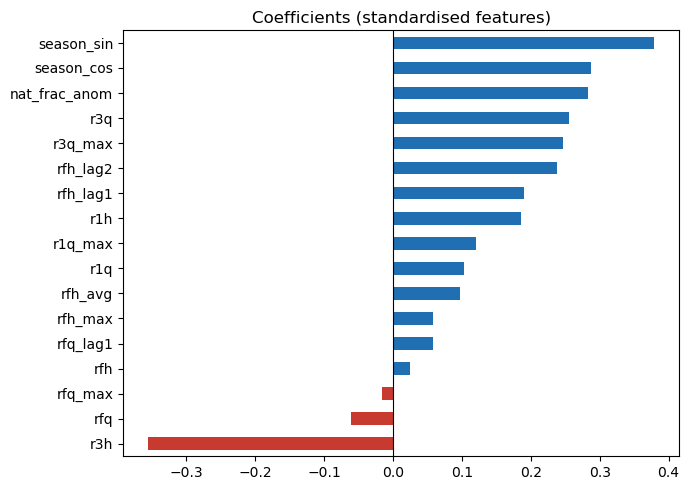

In [17]:
model = make_model().fit(train[COUNTY_BASE], train.flooded)
coef = pd.Series(model.named_steps["logisticregression"].coef_[0], index=COUNTY_BASE).sort_values()
ax = coef.plot(kind="barh", figsize=(7, 5), color=["#C8392F" if v < 0 else "#1F6FB2" for v in coef])
ax.set_title("Coefficients (standardised features)"); ax.axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()

## 5. Evaluation on the unseen years (2020–2024)

Precision is how often an alert was right; recall is how many floods were caught; lift is PR-AUC divided by the base rate (how many times better than random). We compare with two simple rules: the plain rule (at least 50 mm) and the combined rule (at least 50 mm and at least 200% of normal). An event is a run of flooded dekads in one county; it is caught if an alert came within one dekad. A credible alert episode is one within one dekad of a recorded flood. This reproduces our one-shot final test exactly, without changing anything.

In [18]:
from pipeline.final_run import event_metrics
test["prob"] = model.predict_proba(test[COUNTY_BASE])[:, 1]
test["model"] = (test.prob >= threshold).astype(int)
test["plain"] = (test.rfh_max >= 50).astype(int)
test["combined"] = ((test.rfh_max >= 50) & (test.rfq_max >= 200)).astype(int)

base_rate = test.flooded.mean(); pr_auc = average_precision_score(test.flooded, test.prob)
print(f"test rows {len(test)}, floods {int(test.flooded.sum())}, base rate {base_rate:.3f}")
print(f"model PR-AUC {pr_auc:.3f}  (lift {pr_auc/base_rate:.1f}x)")

rows = []
for name in ["plain", "combined", "model"]:
    alerts = int(test[name].sum()); tp = int(((test[name] == 1) & (test.flooded == 1)).sum())
    ev, caught, ep, cred = event_metrics(test, name)
    rows.append({"method": name, "alerts": alerts, "precision": round(tp/alerts, 3),
                 "recall": round(tp/test.flooded.sum(), 3),
                 "events caught": f"{caught}/{ev} ({100*caught/ev:.0f}%)",
                 "credible alerts": f"{cred}/{ep} ({100*cred/ep:.1f}%)"})
results = pd.DataFrame(rows); results

test rows 8460, floods 285, base rate 0.034
model PR-AUC 0.116  (lift 3.4x)


,method,alerts,precision,recall,events caught,credible alerts
0,plain,2291,0.081,0.653,69/79 (87%),80/939 (8.5%)
1,combined,733,0.106,0.274,51/79 (65%),59/550 (10.7%)
2,model,1903,0.086,0.572,62/79 (78%),61/452 (13.5%)


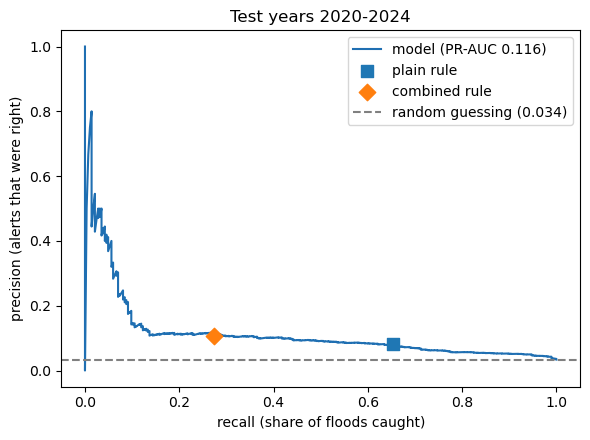

In [19]:
# precision-recall curve, with the two rules as single points
p, r, _ = precision_recall_curve(test.flooded, test.prob)
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(r, p, color="#1F6FB2", label=f"model (PR-AUC {pr_auc:.3f})")
for name, mk in [("plain", "s"), ("combined", "D")]:
    tp = ((test[name] == 1) & (test.flooded == 1)).sum()
    ax.scatter(tp/test.flooded.sum(), tp/test[name].sum(), marker=mk, s=70, zorder=3, label=f"{name} rule")
ax.axhline(base_rate, ls="--", color="grey", label=f"random guessing ({base_rate:.3f})")
ax.set_xlabel("recall (share of floods caught)"); ax.set_ylabel("precision (alerts that were right)")
ax.set_title("Test years 2020-2024"); ax.legend(); plt.tight_layout(); plt.show()

In [20]:
# confusion matrix at the chosen threshold
pd.crosstab(test.flooded.map({1: "really flooded", 0: "not flooded"}),
            test.model.map({1: "model alert", 0: "no alert"}))

model,model alert,no alert
flooded,,
not flooded,1740,6435
really flooded,163,122


The model is about 3.4 times better than random and catches far more floods than the strict rule, though it is only slightly better than the plain 50 mm rule. Most alerts are not near a recorded flood. Some of these are probably real floods that were never recorded (for example April 2024, when agencies reported many more affected counties than the databases show), but we cannot prove that yet.

## 6. Deployment: calibration, explanations and export to the app

Because training gave floods extra weight, the raw probability is inflated, so we never show it. Calibration maps each raw score to the real share of floods in past years with similar scores (isotonic regression, using steps of at least 200 rows so each step is reliable). The app rounds the chance to the nearest 5% and shows 'under 5%' instead of 0%. The three reasons come from adding up each feature group's push and taking the three biggest.

In [21]:
%run pipeline/export_model.py --out export/model.json

normals vs training rfh_avg: max difference 0.0001 mm

app-style features vs real, 30456 training county dekads:
  mean abs difference (points of % of normal): rfq 0.45  rfq_lag1 0.45  r1q 0.42  r3q 0.30
  probability: mean diff 0.0045, 95th pct 0.0199, corr 0.9991
  high / not-high differs on 0.31% of rows (true alerts 3802, app alerts 3709)

row  county  date        sklearn   score()   diff
37865KE046   2018-10-21  0.537379  0.537379  0.0e+00
23594KE029   2013-05-21  0.370107  0.370107  0.0e+00
16715KE021   2006-04-21  0.773903  0.773903  0.0e+00
25050KE031   2007-11-01  0.296496  0.296496  0.0e+00
27907KE034   2018-03-11  0.987932  0.987932  0.0e+00

largest difference over 3000 rows: 2.22e-16

calibration: 23 steps, every one with >= 200 rows; calibrate() vs numpy interp: 0.0e+00
  rows  floods  raw range        chance
   2151     10  0.051-0.128    0.005
   2901     18  0.128-0.170    0.006
    866      8  0.170-0.181    0.009
    307      3  0.181-0.186    0.010
   3461     42  0

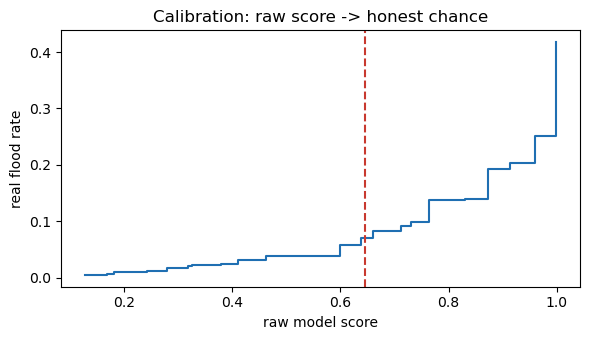

In [22]:
from pipeline.export_model import score, calibrate, display_chance, group_contributions, app_features
m = json.loads(Path("export/model.json").read_text())

steps = pd.DataFrame(m["calibration"]["steps"])
ax = steps.plot(x="raw_to", y="chance", drawstyle="steps-post", legend=False, figsize=(6, 3.5), color="#1F6FB2")
ax.axvline(m["threshold"], ls="--", color="#C8392F"); ax.set_xlabel("raw model score"); ax.set_ylabel("real flood rate")
ax.set_title("Calibration: raw score -> honest chance"); plt.tight_layout(); plt.show()

In [ ]:
# explainable AI: Nairobi on 21 April 2024, the dekad the app replays
row = df[(df.county == "KE047") & (df.date == "2024-04-21")].iloc[0]
feats = {f: row[f] for f in COUNTY_BASE}
p = score(feats, m)
print(f"raw score {p:.3f} | band {'high' if p >= m['threshold'] else 'elevated' if p >= 0.5 else 'low'}"
      f" | calibrated chance {calibrate(p, m):.3f} | shown as {display_chance(p, m):.0%}")
pd.Series(group_contributions(feats, m)).sort_values(ascending=False).round(3).rename("push on the risk score")

raw score 0.991 | band high | calibrated chance 0.418 | shown as 40%


past_month       3.357
past_3_months    0.904
rest_of_kenya    0.630
time_of_year     0.402
this_10_days     0.164
Name: push on the risk score, dtype: float64

In [ ]:
# the app builds features from a user's inputs and runs the same maths on the phone.
# Shared test case: the Android app returned 0.058431952662721894 for this input.
x = app_features("KE006", 12, 50, 30, 25, 180, 0.4, m)
print("Python reference:", calibrate(score(x, m), m))

Python reference: 0.058431952662721894


## 7. Conclusion and limitations

MajiAlert turns open satellite rainfall into county flood risk with a calibrated chance and plain-language reasons. On 2020-2024, years it never saw, it was 3.4 times better than chance and caught 78% of flood events. Limitations: it only sees rainfall (not dams or drainage), it learns only recorded floods, it estimates current risk rather than forecasting, and its precision is low, so it helps prioritise rather than predict exactly. Next steps are forecast mode, checking false alarms against news reports, and push notifications.